# 5a — Main Network Hazard Criticality, Costa Rica

## Purpose
Cross the single-point-of-failure criticality results of notebook 2 with the hazard exposure
layer of notebook 4a, and report which hazardous roads matter for travel.

**This is hazard-screened criticality, not risk.** Nothing here models what a flood or a landslide
*does* to a road. VHL / PHL / TKL are the losses that would occur if a road were **fully closed**,
taken from notebook 2's percolation, and reported for the subset of roads that intersect a hazard
footprint. There is no fragility curve, no depth-damage relationship, no closure probability and no
expected annual loss. Every figure captioned "VHL under flood" means *"VHL of roads that the RP100
model floods"*, not *"VHL caused by flooding"*.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/physical_criticality_results.gpkg` | SPOF criticality, 5,012 physical roads (step 2) |
| `intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg` | SPOF criticality, 9,764 directed edges (step 2) |
| `intermediate_results/gpkg/hazard_exposure/main_network_hazard_exposure.gpkg` | Hazard exposure, 9,764 directed edges x 41 columns (step 4a) |

No raster is opened here. All hazard sampling happens in 4a; this notebook joins, crosses and maps.
No socioeconomic layer is read either — the IDS quintile crossing lives in 5d (plan decision D4).

## Outputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/main_network_hazard_criticality.gpkg` | Layers `physical` (5,012) and `directed` (9,764), EPSG:8908 |
| `figures/hazard_criticality_vhl_1x3.png` | VHL on roads exposed to each of the three scored hazards |
| `figures/hazard_criticality_flood_min_rp.png` | Flood exceedance: shortest return period at which a road floods |
| `figures/hazard_criticality_score.png` | Graded multi-hazard score |
| `figures/hazard_criticality_flood_share.png` | How much of a "flooded" road is actually wet |

## Key processing steps
1. **Load and join** the three inputs; verify the join is 1:1 and loses no row.
2. **Aggregate hazards to the physical road**, the level at which criticality metrics are not
   double-counted and the level 5d works at.
3. **Cross** each hazard against every disruption metric, always beside its length share.
4. **Isolation subset** — roads that both disconnect places and sit in a hazard footprint.
5. **Graded multi-hazard score** — no equal-weight binary count.
6. **Map and save**, keeping every road.

## Assumptions recorded in this notebook
- **Reporting level is the physical road (5,012).** Criticality metrics at directed-edge level
  double-count a two-way road, and `road_length` summed over directed edges is **29,528 km against
  a true network length of 14,810 km**. Every length share in 4a used that doubled denominator;
  shares are unaffected (both directed edges of a road carry identical hazard values) but absolute
  kilometres are not, so they are recomputed here.
- **Hazards aggregate to the physical road with `max`** (worst of the two directed edges). The two
  edges of a road share a geometry and therefore their sampled values; the spread between them is
  printed in section 3 and is zero to within floating-point representation, so the choice of
  aggregator is immaterial here.
- **`precip_anomaly` is excluded from the score.** It is observed 2025 against a 2000-2024
  climatology — a description of one year, not a recurrence probability, and not commensurate with
  an RP100 depth or a 20-year return level. It is carried as context only.
- **Flood is scored by exceedance frequency, not by depth.** `flood_min_rp` from 4a is the D2 rule
  (deepest point above 0.25 m) applied to all seven JRC return periods.
- **The score is an ordinal composite, not a probability.** Each hazard is banded, normalised to
  0-1 and averaged. It ranks roads; it does not estimate anything.
- Hazard exposure inherits every caveat recorded in 4a — the uncalibrated bridge mask, the
  inherited 0.25 m threshold, Rx1month standing in for Rx1day, and LHASA susceptibility being a
  modelled propensity rather than an observed inventory.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [2]:
# ---- Paths ---------------------------------------------------------------
BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

# Shared CR map style: extent, basemap, outline, cities, legend (src/map_style_cr.py)
import sys
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from src.map_style_cr import add_cr_legend, style_cr_map

disruption_dir = intermediate_path / "gpkg" / "travel_disruptions"
physical_gpkg = disruption_dir / "physical_criticality_results.gpkg"
directed_gpkg = disruption_dir / "criticality_results.gpkg"
hazard_gpkg = intermediate_path / "gpkg" / "hazard_exposure" / "main_network_hazard_exposure.gpkg"
out_gpkg = disruption_dir / "main_network_hazard_criticality.gpkg"

figure_path.mkdir(parents=True, exist_ok=True)

# ---- Constants -----------------------------------------------------------
WORKING_EPSG = 8908           # CR-SIRGAS / CRTM05, metres
DPI = 300

# Disruption metrics carried through every crossing, in the order reported.
METRICS = ["vhl", "vkl", "phl", "thl", "pkl", "tkl"]
METRIC_LABELS = {
    "vhl": "Vehicle hours lost",
    "vkl": "Vehicle km lost",
    "phl": "Passenger hours lost",
    "thl": "Ton hours lost",
    "pkl": "Passenger km lost",
    "tkl": "Ton km lost",
}

# Flood exceedance bands (plan issue I4). Shorter return period = more frequent = worse.
# 0 means "never floods at any modelled return period up to 500 years".
FLOOD_RP_BANDS = {500.0: 1, 200.0: 2, 100.0: 3, 75.0: 4, 50.0: 5, 20.0: 6, 10.0: 7}
FLOOD_BAND_MAX = 7
LANDSLIDE_BAND_MAX = 5        # LHASA classes 0-5, used as an ordinal score (decision D3)
RAIN_BANDS = {"Low": 0, "Moderate": 1, "High": 2, "Very high": 3}
RAIN_BAND_MAX = 3

print(f"physical criticality : {physical_gpkg.name}  (exists: {physical_gpkg.exists()})")
print(f"directed criticality : {directed_gpkg.name}  (exists: {directed_gpkg.exists()})")
print(f"hazard exposure      : {hazard_gpkg.name}  (exists: {hazard_gpkg.exists()})")
print(f"output               : {out_gpkg.relative_to(BASE_DIR)}")

physical criticality : physical_criticality_results.gpkg  (exists: True)
directed criticality : criticality_results.gpkg  (exists: True)
hazard exposure      : main_network_hazard_exposure.gpkg  (exists: True)
output               : intermediate_results/gpkg/travel_disruptions/main_network_hazard_criticality.gpkg


## 2. Load and join

The three inputs all descend from `main_network_directed.gpkg`, so the joins are exact. They are
asserted rather than assumed: a silent row loss here would propagate into every number below.

In [3]:
physical = gpd.read_file(physical_gpkg)
directed = gpd.read_file(directed_gpkg)
hazard = gpd.read_file(hazard_gpkg)

print(f"physical criticality : {len(physical):,} roads   ({physical.crs})")
print(f"directed criticality : {len(directed):,} edges   ({directed.crs})")
print(f"hazard exposure      : {len(hazard):,} edges x {len(hazard.columns)} cols  ({hazard.crs})")

# The joins must be exact and 1:1 -- fail loudly rather than lose rows quietly.
assert directed["id"].is_unique and hazard["id"].is_unique, "id is not unique"
assert set(directed["id"]) == set(hazard["id"]), "directed / hazard id sets differ"
assert physical["physical_edge_id"].is_unique, "physical_edge_id is not unique"
assert set(physical["physical_edge_id"]) == set(hazard["physical_edge_id"]), \
    "physical / hazard physical_edge_id sets differ"

TRUE_NETWORK_KM = physical["road_length"].sum()
print(f"\nnetwork length: {TRUE_NETWORK_KM:,.0f} km at physical-road level")
print(f"               {directed['road_length'].sum():,.0f} km summed over directed edges "
      f"(each two-way road counted twice -- NOT the network length)")

physical criticality : 5,012 roads   (EPSG:8908)
directed criticality : 9,764 edges   (EPSG:8908)
hazard exposure      : 9,764 edges x 41 cols  (EPSG:8908)

network length: 14,811 km at physical-road level
               29,528 km summed over directed edges (each two-way road counted twice -- NOT the network length)


## 3. Aggregate hazards to the physical road

Criticality is reported per physical road; hazards are sampled per directed edge. Because the two
directed edges of one road share a geometry they also share their hazard values, so the aggregation
is `max` (worst of the pair) and is effectively a no-op — verified below.

In [4]:
hazard_value_cols = [
    "flood_value", "flood_share_gt0p25", "flood_depth_implausible", "flood_min_rp",
    "flood_aep", "flood_rp_censored", "max_at_crossing",
    "landslide_value", "precip_anomaly_value", "precip_rx1month_value",
    "n_water_crossings", "has_temporary_structure",
    # D6 regime flags -- these MUST travel with the rows. Without them a consumer
    # cannot tell whether a flood number was produced with or without the DEM
    # correction, and the two are not comparable (plan issue I1c).
    "flood_correction_applied", "road_freeboard_m", "flood_depth_dem_corrected",
]
hazard_class_cols = ["flood_class", "landslide_class", "precip_anomaly_class",
                     "precip_rx1month_class"]

numeric = hazard.groupby("physical_edge_id")[hazard_value_cols].max()
# Class labels are text; take the first (both edges agree by construction).
classes = hazard.groupby("physical_edge_id")[hazard_class_cols].first()
per_road = numeric.join(classes)

# How often do the two directed edges actually disagree?
spread = hazard.groupby("physical_edge_id")[
    ["flood_value", "landslide_value", "precip_rx1month_value"]
].agg(lambda s: s.max() - s.min())
print("max-minus-min across the two directed edges of a road:")
for col in spread.columns:
    print(f"  {col:<24} max spread {spread[col].max():.6f}  "
          f"({int((spread[col] > 1e-9).sum()):,} roads non-zero)")

gdf = physical.merge(per_road, left_on="physical_edge_id", right_index=True,
                     how="inner", validate="1:1")
assert len(gdf) == len(physical), "join changed the row count"
print(f"\njoined: {len(gdf):,} physical roads x {len(gdf.columns)} columns")

max-minus-min across the two directed edges of a road:
  flood_value              max spread 0.000000  (0 roads non-zero)
  landslide_value          max spread 0.000000  (0 roads non-zero)
  precip_rx1month_value    max spread 0.000000  (0 roads non-zero)

joined: 5,012 physical roads x 53 columns


## 4. Hazard × criticality crossing

For each hazard: how much of the network it selects, and how much of each disruption metric sits on
the roads it selects. **The length share is always printed beside the metric share**, because a
hazard that flags 70 % of the network will carry roughly 70 % of anything. The interesting quantity
is the gap between the two, not the metric share on its own.

Hazard definitions here are 4a's, with landslide shown at two cuts because decision D3 uses it as a
graded score and any single binary cut is arbitrary.

In [5]:
hazard_masks = {
    "Flood (RP100, > 0.25 m)": gdf["flood_value"] > 0.25,
    "Flood (frequent, <= RP20)": gdf["flood_min_rp"].fillna(np.inf) <= 20,
    "Landslide (High+, LHASA >= 4)": gdf["landslide_value"] >= 4,
    "Landslide (Very high, LHASA = 5)": gdf["landslide_value"] >= 5,
    "Rx1month (High+, >= 750 mm)": gdf["precip_rx1month_value"] >= 750,
    "Water crossing (>= 1 structure)": gdf["n_water_crossings"] >= 1,
    "Temporary structure": gdf["has_temporary_structure"].astype(bool),
}

rows = []
for name, mask in hazard_masks.items():
    mask = np.asarray(mask, dtype=bool)
    row = {
        "hazard": name,
        "roads": int(mask.sum()),
        "km": gdf.loc[mask, "road_length"].sum(),
        "length_share": gdf.loc[mask, "road_length"].sum() / TRUE_NETWORK_KM,
    }
    for metric in METRICS:
        row[f"{metric}_share"] = (
            gdf.loc[mask, metric].sum() / gdf[metric].sum() if gdf[metric].sum() else np.nan
        )
    rows.append(row)

crossing = pd.DataFrame(rows)
# "Lift" = metric share divided by length share. 1.0 means the hazard picks up exactly its
# proportional share of the metric; > 1 means it concentrates on roads that matter more.
for metric in METRICS:
    crossing[f"{metric}_lift"] = crossing[f"{metric}_share"] / crossing["length_share"]

show = ["hazard", "roads", "km", "length_share", "vhl_share", "vhl_lift", "phl_share",
        "phl_lift", "tkl_share", "tkl_lift"]
print(crossing[show].to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
print("\nlift = metric share / length share. 1.0 = proportional; > 1 = concentrates on "
      "roads carrying more traffic.")

                          hazard  roads        km  length_share  vhl_share  vhl_lift  phl_share  phl_lift  tkl_share  tkl_lift
         Flood (RP100, > 0.25 m)    378 2,419.550         0.163      0.266     1.625      0.271     1.658      0.211     1.293
       Flood (frequent, <= RP20)    352 2,300.208         0.155      0.235     1.514      0.241     1.551      0.203     1.309
   Landslide (High+, LHASA >= 4)   1764 7,971.951         0.538      0.423     0.786      0.428     0.795      0.331     0.615
Landslide (Very high, LHASA = 5)   1058 5,476.640         0.370      0.268     0.724      0.274     0.742      0.190     0.513
     Rx1month (High+, >= 750 mm)   1448 6,110.140         0.413      0.338     0.819      0.340     0.824      0.519     1.257
 Water crossing (>= 1 structure)   1036 4,839.076         0.327      0.401     1.227      0.410     1.256      0.646     1.976
             Temporary structure    226 1,523.531         0.103      0.129     1.258      0.135     1.313      

In [6]:
# ---- The isolation subset -------------------------------------------------
# Roads whose failure disconnects origins from destinations entirely, rather than
# merely delaying them. These are the operational headline when crossed with hazard.
isolating = gdf["pct_isolated"] > 0
print(f"roads that isolate when closed: {int(isolating.sum()):,} of {len(gdf):,} "
      f"({gdf.loc[isolating, 'road_length'].sum():,.0f} km, "
      f"{gdf.loc[isolating, 'road_length'].sum() / TRUE_NETWORK_KM:.1%} of length)")
print()
for name, mask in hazard_masks.items():
    mask = np.asarray(mask, dtype=bool) & np.asarray(isolating, dtype=bool)
    if mask.sum():
        print(f"  {name:<34} {int(mask.sum()):>4} isolating roads  "
              f"{gdf.loc[mask, 'road_length'].sum():>7,.0f} km  "
              f"VHL {gdf.loc[mask, 'vhl'].sum():>12,.0f}")
    else:
        print(f"  {name:<34} {0:>4} isolating roads")

roads that isolate when closed: 130 of 5,012 (578 km, 3.9% of length)

  Flood (RP100, > 0.25 m)              35 isolating roads      253 km  VHL    2,632,340
  Flood (frequent, <= RP20)            32 isolating roads      205 km  VHL    2,273,736
  Landslide (High+, LHASA >= 4)        71 isolating roads      404 km  VHL    4,032,810
  Landslide (Very high, LHASA = 5)     47 isolating roads      297 km  VHL    2,552,102
  Rx1month (High+, >= 750 mm)          38 isolating roads      220 km  VHL    3,049,785
  Water crossing (>= 1 structure)      37 isolating roads      204 km  VHL    3,224,869
  Temporary structure                  12 isolating roads       95 km  VHL    1,134,227


## 5. Graded multi-hazard score

Serbia counted six hazards with equal weight, so a road under three metres of water and a road
1 sigma wetter than normal each scored 1. That is replaced here by an **ordinal composite**.

Each hazard is banded, normalised to 0-1, and the bands are averaged:

| Component | Band | Source |
|---|---|---|
| `flood_band` | 0-7 by exceedance frequency: 0 never, 1 RP500 … 7 RP10 | `flood_min_rp` (4a) |
| `landslide_band` | 0-5, the LHASA class used directly as an ordinal (decision D3) | `landslide_value` |
| `rain_band` | 0-3 from the Rx1month 20-year return-level class | `precip_rx1month_class` |

`precip_anomaly` is deliberately absent — see the header.

**What the score is not.** It is not a probability, not an expected loss, and not calibrated
against anything observed. Averaging three ordinals asserts that they matter equally, which is a
convention, not a finding. It is useful for ranking roads and nothing more.

In [7]:
gdf["flood_band"] = gdf["flood_min_rp"].map(FLOOD_RP_BANDS).fillna(0).astype(int)
gdf["landslide_band"] = gdf["landslide_value"].fillna(0).clip(0, LANDSLIDE_BAND_MAX).astype(int)
gdf["rain_band"] = gdf["precip_rx1month_class"].map(RAIN_BANDS).fillna(0).astype(int)

gdf["hazard_score"] = (
    gdf["flood_band"] / FLOOD_BAND_MAX
    + gdf["landslide_band"] / LANDSLIDE_BAND_MAX
    + gdf["rain_band"] / RAIN_BAND_MAX
) / 3.0

for col, cap in [("flood_band", FLOOD_BAND_MAX), ("landslide_band", LANDSLIDE_BAND_MAX),
                 ("rain_band", RAIN_BAND_MAX)]:
    counts = gdf[col].value_counts().sort_index()
    body = "  ".join(f"{band}:{n:,}" for band, n in counts.items())
    print(f"{col:<16} (0-{cap})  {body}")

print(f"\nhazard_score: min {gdf['hazard_score'].min():.3f}  "
      f"median {gdf['hazard_score'].median():.3f}  max {gdf['hazard_score'].max():.3f}")
print(f"roads with score 0 (no hazard at all): {int((gdf['hazard_score'] == 0).sum()):,}")

# The flood band is heavily saturated: 4a found 86% of ever-flooded roads already flood at
# RP10, so flood_band is close to binary in practice. Reported so the composite is read
# with that in mind rather than as three evenly-informative axes.
flooded = gdf["flood_band"] > 0
if flooded.any():
    print(f"\nof {int(flooded.sum()):,} roads that ever flood, "
          f"{int((gdf.loc[flooded, 'flood_band'] == FLOOD_BAND_MAX).sum()):,} "
          f"({(gdf.loc[flooded, 'flood_band'] == FLOOD_BAND_MAX).mean():.0%}) are already flooded "
          f"at RP10 -- the flood axis is near-binary in practice")

flood_band       (0-7)  0:4,614  1:9  2:11  3:7  4:10  5:9  6:8  7:344
landslide_band   (0-5)  0:10  1:434  2:1,869  3:935  4:706  5:1,058
rain_band        (0-3)  0:2,277  1:1,287  2:1,030  3:418

hazard_score: min 0.000  median 0.311  max 1.000
roads with score 0 (no hazard at all): 9

of 398 roads that ever flood, 344 (86%) are already flooded at RP10 -- the flood axis is near-binary in practice


In [8]:
# ---- Where does criticality sit within the score? -------------------------
bands = pd.cut(gdf["hazard_score"], bins=[-0.001, 0.0, 0.2, 0.4, 0.6, 1.0],
               labels=["none", "very low", "low", "moderate", "high"])
summary = gdf.groupby(bands, observed=False).agg(
    roads=("physical_edge_id", "size"),
    km=("road_length", "sum"),
    vhl=("vhl", "sum"),
    phl=("phl", "sum"),
    tkl=("tkl", "sum"),
    isolating=("pct_isolated", lambda s: int((s > 0).sum())),
)
summary["km_share"] = summary["km"] / TRUE_NETWORK_KM
summary["vhl_share"] = summary["vhl"] / gdf["vhl"].sum()
print(summary.to_string(float_format=lambda v: f"{v:,.3f}"))

              roads        km           vhl            phl            tkl  isolating  km_share  vhl_share
hazard_score                                                                                             
none              9     1.577        98.524        290.839      9,337.768          0     0.000      0.000
very low       1729 1,758.379 2,871,475.943  9,994,349.472 20,083,379.637         18     0.119      0.235
low            1655 4,895.395 3,254,737.608 12,007,492.882 32,751,007.081         37     0.331      0.266
moderate       1261 5,734.286 3,804,468.861 14,311,277.803 25,422,300.330         49     0.387      0.311
high            358 2,420.906 2,310,421.992  8,675,586.006 21,234,946.029         26     0.163      0.189


## 6. Figures

In [9]:
def _basemap(ax):
    """Grey the whole network, so a selection is read against the country, not in a void."""
    plot_roads.plot(ax=ax, color="#dddddd", linewidth=0.3, zorder=1)


def save_fig(fig, name):
    path = figure_path / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    print(f"saved  {path.relative_to(BASE_DIR)}")


plot_roads = gdf.to_crs(WORKING_EPSG)

# VHL classes shared by the 1x3 panel, so the three maps are comparable.
VHL_BINS = [0, 500, 2_000, 10_000, 50_000, np.inf]
VHL_LABELS = ["< 500", "500 - 2k", "2k - 10k", "10k - 50k", "50k+"]
VHL_COLORS = ["#fdd0a2", "#fdae6b", "#fd8d3c", "#e6550d", "#a63603"]
VHL_WIDTHS = [0.4, 0.6, 0.9, 1.3, 1.8]

saved  figures/hazard_criticality_vhl_1x3.png


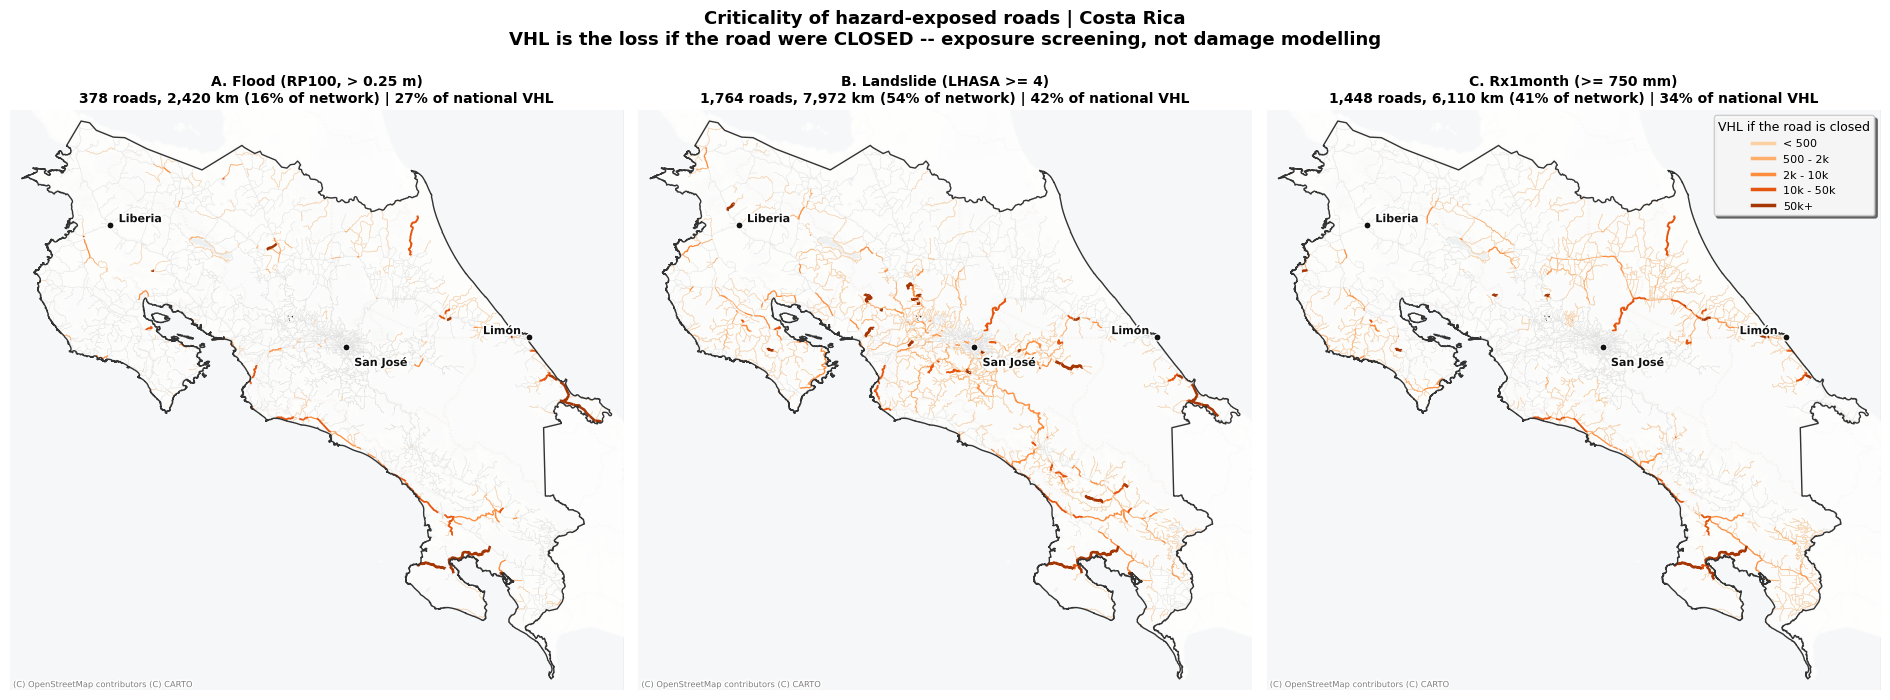

In [10]:
# ---- 1x3: VHL on roads exposed to each scored hazard ----------------------
panels = [
    ("A. Flood (RP100, > 0.25 m)", gdf["flood_value"] > 0.25),
    ("B. Landslide (LHASA >= 4)", gdf["landslide_value"] >= 4),
    ("C. Rx1month (>= 750 mm)", gdf["precip_rx1month_value"] >= 750),
]

fig, axes = plt.subplots(1, 3, figsize=(19, 7))
for ax, (title, mask) in zip(axes, panels):
    _basemap(ax)
    mask = np.asarray(mask, dtype=bool)
    sub = plot_roads[mask].copy()
    sub["cls"] = pd.cut(sub["vhl"], bins=VHL_BINS, labels=VHL_LABELS, include_lowest=True)
    for label, colour, width in zip(VHL_LABELS, VHL_COLORS, VHL_WIDTHS):
        part = sub[sub["cls"] == label]
        if not part.empty:
            part.plot(ax=ax, color=colour, linewidth=width, zorder=3)
    ax.set_title(
        f"{title}\n{int(mask.sum()):,} roads, {gdf.loc[mask, 'road_length'].sum():,.0f} km "
        f"({gdf.loc[mask, 'road_length'].sum() / TRUE_NETWORK_KM:.0%} of network) | "
        f"{gdf.loc[mask, 'vhl'].sum() / gdf['vhl'].sum():.0%} of national VHL",
        fontsize=10, fontweight="bold",
    )

handles = [Line2D([0], [0], color=c, lw=2.5, label=l) for l, c in zip(VHL_LABELS, VHL_COLORS)]
for ax in axes:
    style_cr_map(ax, WORKING_EPSG, city_fontsize=8)
# One shared legend, in the figure's upper-right panel.
add_cr_legend(axes[-1], handles, "VHL if the road is closed", fontsize=8, title_fontsize=9)
fig.suptitle(
    "Criticality of hazard-exposed roads | Costa Rica\n"
    "VHL is the loss if the road were CLOSED -- exposure screening, not damage modelling",
    fontsize=13, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "hazard_criticality_vhl_1x3.png")
plt.show()

saved  figures/hazard_criticality_flood_min_rp.png


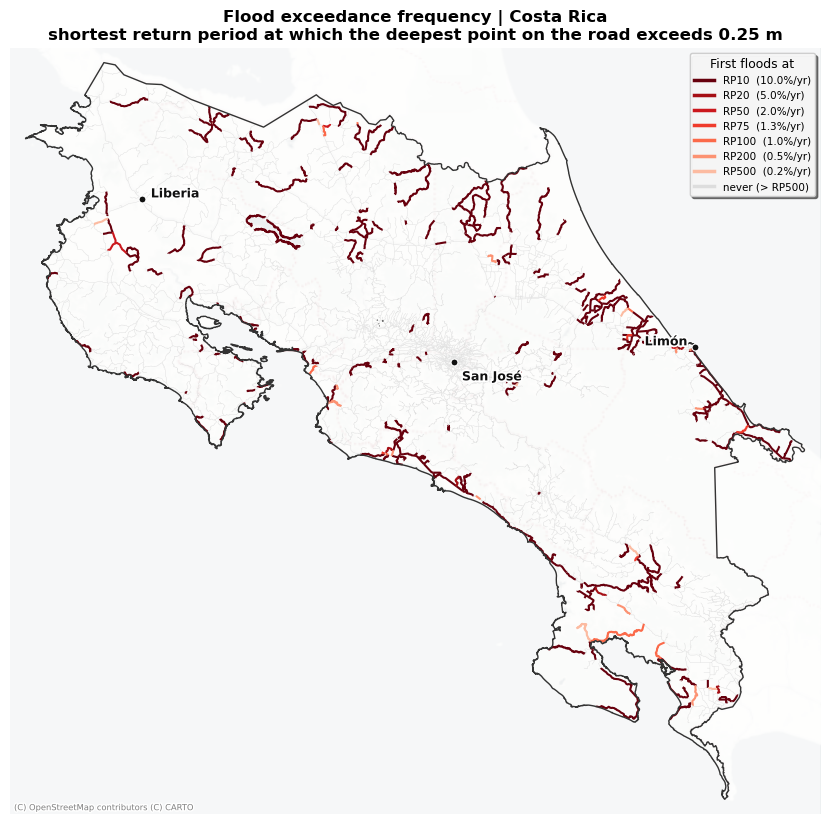

In [11]:
# ---- Flood exceedance: how often does a road flood? -----------------------
RP_ORDER = [10.0, 20.0, 50.0, 75.0, 100.0, 200.0, 500.0]
RP_COLORS = ["#67000d", "#a50f15", "#cb181d", "#ef3b2c", "#fb6a4a", "#fc9272", "#fcbba1"]

fig, ax = plt.subplots(figsize=(9.5, 8.5))
_basemap(ax)
for rp, colour in zip(RP_ORDER, RP_COLORS):
    part = plot_roads[plot_roads["flood_min_rp"] == rp]
    if not part.empty:
        part.plot(ax=ax, color=colour, linewidth=1.5, zorder=4)

handles = [
    Line2D([0], [0], color=c, lw=2.5, label=f"RP{int(rp)}  ({1 / rp:.1%}/yr)")
    for rp, c in zip(RP_ORDER, RP_COLORS)
    if (plot_roads["flood_min_rp"] == rp).any()
]
handles.append(Line2D([0], [0], color="#dddddd", lw=2.5, label="never (> RP500)"))
style_cr_map(ax, WORKING_EPSG, legend_handles=handles, legend_title="First floods at")
ax.set_title(
    "Flood exceedance frequency | Costa Rica\n"
    "shortest return period at which the deepest point on the road exceeds 0.25 m",
    fontsize=12, fontweight="bold",
)
plt.tight_layout()
save_fig(fig, "hazard_criticality_flood_min_rp.png")
plt.show()

saved  figures/hazard_criticality_flood_share.png


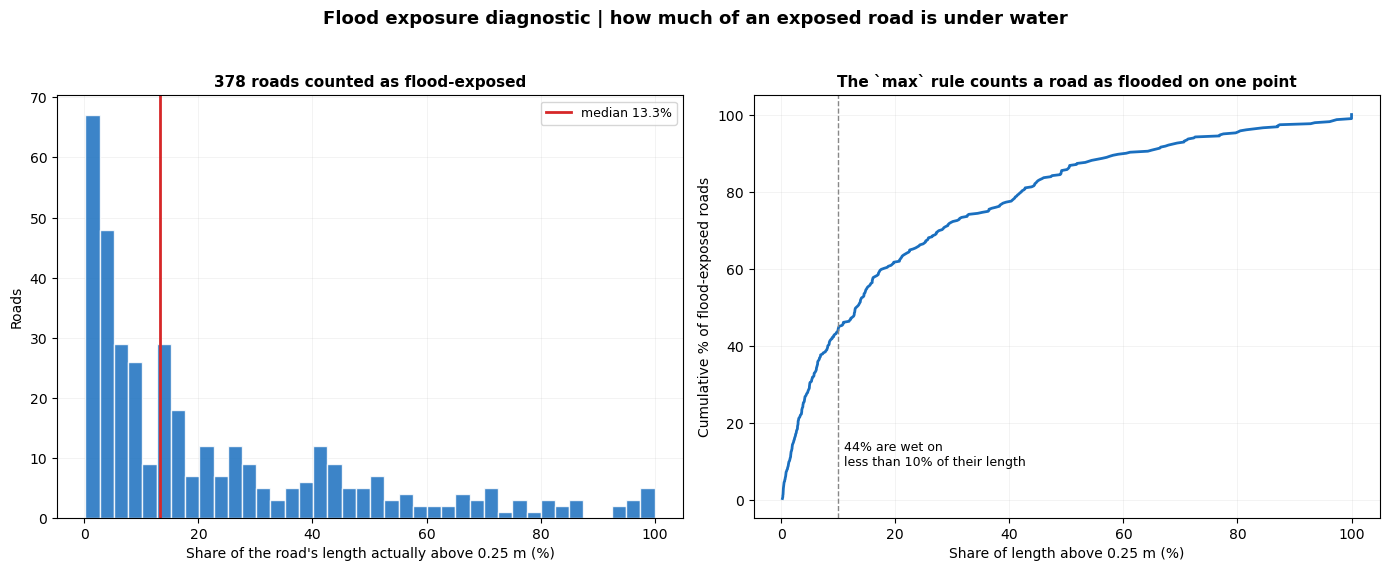

In [12]:
# ---- How much of a "flooded" road is actually wet? ------------------------
# The exposure rule is `max` (decision D2), so a road counts as flooded on the strength of
# one point. This is the diagnostic that keeps that visible.
flooded = gdf["flood_value"] > 0.25
share = gdf.loc[flooded, "flood_share_gt0p25"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].hist(share * 100, bins=40, color="#1a6fbf", alpha=0.85, edgecolor="white")
axes[0].axvline(share.median() * 100, color="#d62728", lw=2,
                label=f"median {share.median():.1%}")
axes[0].set_xlabel("Share of the road's length actually above 0.25 m (%)", fontsize=10)
axes[0].set_ylabel("Roads", fontsize=10)
axes[0].legend(fontsize=9)
axes[0].set_title(f"{int(flooded.sum()):,} roads counted as flood-exposed", fontsize=11,
                  fontweight="bold")

cum = np.sort(share.to_numpy())
axes[1].plot(cum * 100, np.arange(1, len(cum) + 1) / len(cum) * 100, color="#1a6fbf", lw=2)
axes[1].axvline(10, color="#888888", ls="--", lw=1)
axes[1].text(11, 8, f"{(share < 0.10).mean():.0%} are wet on\nless than 10% of their length",
             fontsize=9, va="bottom")
axes[1].set_xlabel("Share of length above 0.25 m (%)", fontsize=10)
axes[1].set_ylabel("Cumulative % of flood-exposed roads", fontsize=10)
axes[1].set_title("The `max` rule counts a road as flooded on one point", fontsize=11,
                  fontweight="bold")
for ax in axes:
    ax.grid(alpha=0.25, linewidth=0.4)
    ax.set_axisbelow(True)

fig.suptitle("Flood exposure diagnostic | how much of an exposed road is under water",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "hazard_criticality_flood_share.png")
plt.show()

saved  figures/hazard_criticality_score.png


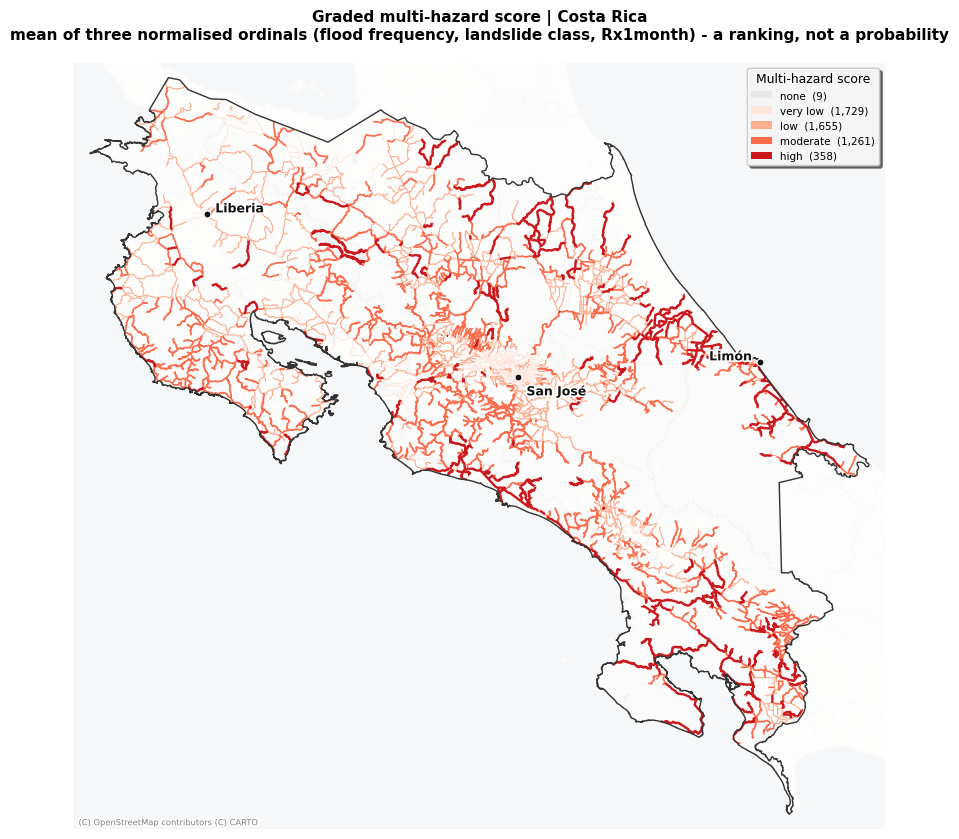

In [13]:
# ---- Graded multi-hazard score --------------------------------------------
SCORE_BINS = [-0.001, 0.0, 0.2, 0.4, 0.6, 1.0]
SCORE_LABELS = ["none", "very low", "low", "moderate", "high"]
SCORE_COLORS = ["#e8e8e8", "#fee5d9", "#fcae91", "#fb6a4a", "#cb181d"]
SCORE_WIDTHS = [0.3, 0.5, 0.8, 1.2, 1.7]

plot_roads["score_class"] = pd.cut(plot_roads["hazard_score"], bins=SCORE_BINS,
                                   labels=SCORE_LABELS)

fig, ax = plt.subplots(figsize=(9.5, 8.5))
for label, colour, width in zip(SCORE_LABELS, SCORE_COLORS, SCORE_WIDTHS):
    part = plot_roads[plot_roads["score_class"] == label]
    if not part.empty:
        part.plot(ax=ax, color=colour, linewidth=width, zorder=2 + SCORE_LABELS.index(label))

handles = [Patch(facecolor=c, label=f"{l}  ({int((plot_roads['score_class'] == l).sum()):,})")
           for l, c in zip(SCORE_LABELS, SCORE_COLORS)]
style_cr_map(ax, WORKING_EPSG, legend_handles=handles, legend_title="Multi-hazard score")
ax.set_title(
    "Graded multi-hazard score | Costa Rica\n"
    "mean of three normalised ordinals (flood frequency, landslide class, Rx1month) "
    "- a ranking, not a probability",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
save_fig(fig, "hazard_criticality_score.png")
plt.show()

## 7. Save

Two layers, both complete. **No road is dropped for being hazard-free** — the Serbia notebook
filtered those out, which left the saved layer unusable as a denominator and meant 5d scored a
pre-filtered set.

In [14]:
keep_physical = [
    "physical_edge_id", "ID_TRAMO", "ID_RUTA", "NOMBRE", "CLASE", "ADMIN",
    "road_length", "speed", "total_aadt", "aadt_imputed",
    "pct_isolated", "pct_unaffected", "pct_delayed",
    "average_time_disruption", "average_dist_disruption",
    *METRICS,
    *hazard_value_cols, *hazard_class_cols,
    "flood_band", "landslide_band", "rain_band", "hazard_score",
    "geometry",
]
keep_physical = [c for c in keep_physical if c in gdf.columns]
out_physical = gdf[keep_physical].to_crs(WORKING_EPSG)

# The directed layer is the hazard table joined to the directed criticality results, kept so
# anything working per-edge does not have to re-derive the join.
out_directed = directed.merge(
    hazard.drop(columns=["geometry", "physical_edge_id"]), on="id",
    how="inner", validate="1:1",
).to_crs(WORKING_EPSG)

for frame in (out_physical, out_directed):
    for col in frame.columns:
        if frame[col].dtype.name in ("category", "object") and col != "geometry":
            frame[col] = frame[col].astype("string")

out_physical.to_file(out_gpkg, layer="physical", driver="GPKG")
out_directed.to_file(out_gpkg, layer="directed", driver="GPKG")

print(f"saved  {out_gpkg.relative_to(BASE_DIR)}")
print(f"       layer 'physical': {len(out_physical):,} roads x {len(out_physical.columns)} cols")
print(f"       layer 'directed': {len(out_directed):,} edges x {len(out_directed.columns)} cols")
print(f"       CRS {out_physical.crs}")
print()
print("Carried forward for 5d (plan decision D4 -- the IDS quintile crossing happens there):")
print(f"  join key             : physical_edge_id ({out_physical['physical_edge_id'].nunique():,} unique)")
print(f"  hazard score         : hazard_score, 0-1 ordinal composite")
print(f"  flood term           : flood_aep (annual exceedance probability), 0 where censored")
applied = gdf["flood_correction_applied"].astype("boolean")
print(f"  regime flag from 4a  : flood_correction_applied = {bool(applied.any())} "
      f"({int(applied.fillna(False).sum()):,} of {len(gdf):,} roads corrected)")
assert "flood_correction_applied" in out_physical.columns, "regime flag missing from output"

saved  intermediate_results/gpkg/travel_disruptions/main_network_hazard_criticality.gpkg
       layer 'physical': 5,012 roads x 45 cols
       layer 'directed': 9,764 edges x 81 cols
       CRS EPSG:8908

Carried forward for 5d (plan decision D4 -- the IDS quintile crossing happens there):
  join key             : physical_edge_id (5,012 unique)
  hazard score         : hazard_score, 0-1 ordinal composite
  flood term           : flood_aep (annual exceedance probability), 0 where censored
  regime flag from 4a  : flood_correction_applied = False (0 of 5,012 roads corrected)
